In [ ]:
# This notebook does not represent the final cluster analysis notebook version as it was not done by me. It was only used for comparison of processes and additional visualizations in the final report.

In [42]:
!pip install feature-engine
!pip install country_converter
!pip install plotly
!pip install cufflinks


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import pandas as pd
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from feature_engine.outliers import Winsorizer
from sklearn.cluster import KMeans
from sklearn.metrics import explained_variance_score


In [44]:
import pandas as pd

# Load the CSV file
df_cfs = pd.read_csv(r"C:\Users\Pedro Salgado\Desktop\Nova IMS\Year 2\Semester 1\Data Analysis\Data Analysis PROJECT\yearly_country_factor_scores.csv.xls")

df_cfs.set_index("Country", inplace=True)
df_cfs_factors = df_cfs[["F1", "F2", "F3"]]
df_cfs_factors

,F1,F2,F3
Country,,,
Austria,1.589466,-0.812677,-0.062937
Austria,1.645349,-0.786968,0.331630
Austria,1.808834,-0.616133,0.208787
Belgium,-0.919434,-0.567988,-0.192766
Belgium,-0.962587,-0.664640,0.258340
...,...,...,...
Spain,-0.275989,0.347285,0.205921
Spain,0.121687,1.073335,0.009629
Sweden,0.073115,-0.725288,2.145687


In [45]:


desc = df_cfs_factors.describe()
desc

,F1,F2,F3
count,8.100000e+01,8.100000e+01,8.100000e+01
mean,2.055969e-17,-2.741291e-18,-4.934325e-17
std,9.816973e-01,9.638918e-01,8.562338e-01
min,-1.668357e+00,-1.028199e+00,-1.740059e+00
25%,-6.300624e-01,-6.522776e-01,-5.639005e-01
50%,-2.189356e-01,-3.941498e-01,-5.885047e-02
75%,2.812829e-01,3.472850e-01,4.108455e-01
max,2.570580e+00,3.283066e+00,2.716951e+00


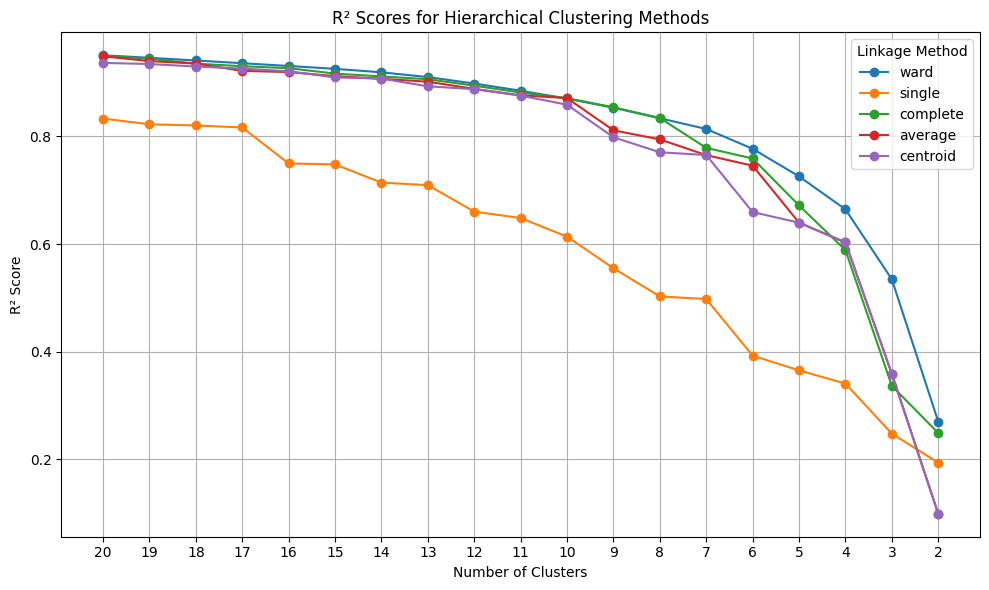

In [46]:
#Choose the best method for hierarchical clustering

methods = ['ward', 'single', 'complete', 'average', 'centroid']
max_clusters = 20

grand_centroid = df_cfs_factors.mean().values
tss = ((df_cfs_factors.values - grand_centroid) ** 2).sum()

results = []

for method in methods:
    Z = linkage(df_cfs_factors, method=method)

    for k in range(2, max_clusters + 1):
        labels = fcluster(Z, k, criterion='maxclust')

        wss = 0
        for cluster_id in np.unique(labels):
            cluster_points = df_cfs_factors.values[labels == cluster_id]
            centroid = cluster_points.mean(axis=0)
            wss += ((cluster_points - centroid) ** 2).sum()

        r_squared = 1 - wss / tss
        results.append({'method': method, 'clusters': k, 'R_squared': r_squared})

df_r2 = pd.DataFrame(results, columns=['method', 'clusters', 'R_squared'])
df_pivot = df_r2.pivot(index='clusters', columns='method', values='R_squared')

# Plot
plt.figure(figsize=(10, 6))
for method in methods:
    plt.plot(df_pivot.index, df_pivot[method], marker='o', label=method)

plt.title('R² Scores for Hierarchical Clustering Methods')
plt.xlabel('Number of Clusters')
plt.ylabel('R² Score')
plt.xticks(df_pivot.index)
plt.legend(title='Linkage Method')
plt.grid(True)
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

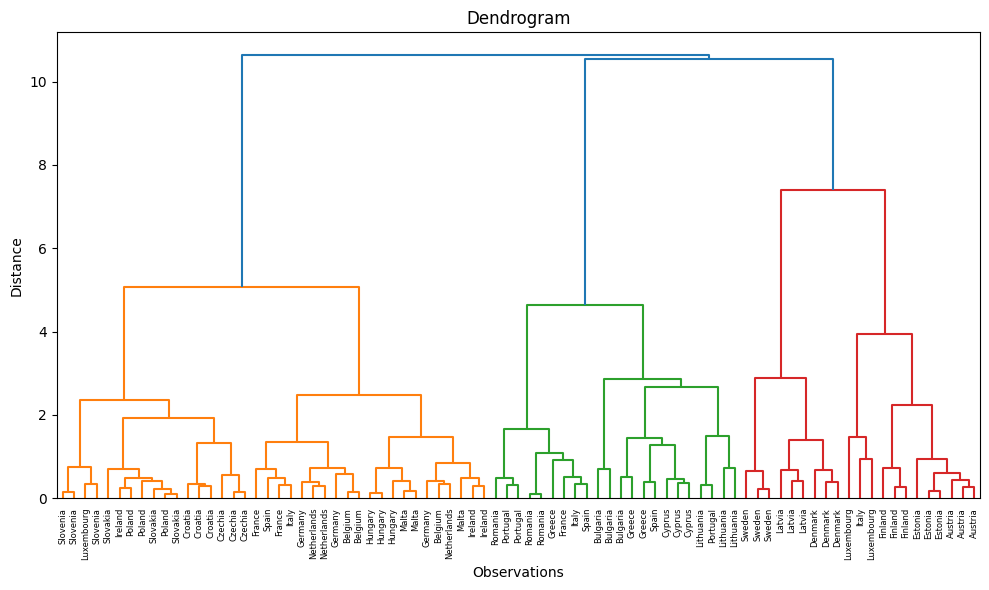

In [47]:
Z = linkage(df_cfs_factors, method="ward")

plt.figure(figsize=(10, 6))
dendrogram(Z, labels=df_cfs_factors.index.tolist(), leaf_rotation=90)
plt.title("Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

In [48]:
#Choose the number of clusters

n_clusters =4

hierarchical_labels = fcluster(Z, n_clusters, criterion="maxclust")

In [49]:
#Assign Hierarchical Clustering Labels

df_cfs_factors['Cluster'] = hierarchical_labels
df_cfs_factors

,F1,F2,F3,Cluster
Country,,,,
Austria,1.589466,-0.812677,-0.062937,4
Austria,1.645349,-0.786968,0.331630,4
Austria,1.808834,-0.616133,0.208787,4
Belgium,-0.919434,-0.567988,-0.192766,1
Belgium,-0.962587,-0.664640,0.258340,1
...,...,...,...,...
Spain,-0.275989,0.347285,0.205921,2
Spain,0.121687,1.073335,0.009629,2
Sweden,0.073115,-0.725288,2.145687,3


In [50]:
#Initial seeds

initial_seeds = df_cfs_factors.groupby("Cluster").mean()
initial_seeds

,F1,F2,F3
Cluster,,,
1,-0.592022,-0.552663,-0.369842
2,-0.048683,1.355893,-0.065754
3,0.109105,-0.357600,1.576158
4,1.882161,-0.467504,0.109596


In [51]:
# Non H Cluster

In [52]:
df_cfs_factors = df_cfs_factors.drop(columns=['Cluster'])
df_cfs_factors

,F1,F2,F3
Country,,,
Austria,1.589466,-0.812677,-0.062937
Austria,1.645349,-0.786968,0.331630
Austria,1.808834,-0.616133,0.208787
Belgium,-0.919434,-0.567988,-0.192766
Belgium,-0.962587,-0.664640,0.258340
...,...,...,...
Spain,-0.275989,0.347285,0.205921
Spain,0.121687,1.073335,0.009629
Sweden,0.073115,-0.725288,2.145687


In [53]:
#Perform Kmeans

kmeans = KMeans(n_clusters = n_clusters , init = initial_seeds.values ) 
kmeans.fit(df_cfs_factors)

,n_clusters,4
,init,array([[-0.59... 0.10959637]])
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [54]:
#Final cluster assignments

df_cfs_factors['kmeans_cluster'] = kmeans.labels_
df_cfs_factors

,F1,F2,F3,kmeans_cluster
Country,,,,
Austria,1.589466,-0.812677,-0.062937,3
Austria,1.645349,-0.786968,0.331630,3
Austria,1.808834,-0.616133,0.208787,3
Belgium,-0.919434,-0.567988,-0.192766,0
Belgium,-0.962587,-0.664640,0.258340,0
...,...,...,...,...
Spain,-0.275989,0.347285,0.205921,0
Spain,0.121687,1.073335,0.009629,1
Sweden,0.073115,-0.725288,2.145687,2


In [55]:
#R2

X = df_cfs_factors.drop(columns=['kmeans_cluster']).values
X_pred = kmeans.cluster_centers_[kmeans.labels_]

r2 = explained_variance_score(X, X_pred)
print(f"Overall R² (Explained Variance): {r2:.3f}")

Overall R² (Explained Variance): 0.658


In [56]:
#R2 of each PC

X = df_cfs_factors.drop(columns=['kmeans_cluster']).copy()
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

r2_per_factor = {}

for i, col in enumerate(X.columns):
    y_true = X[col].values
    y_pred = centroids[labels, i]

    r2 = explained_variance_score(y_true, y_pred)
    r2_per_factor[col] = round(r2, 4)

print("R² per PC:")
for factor, r2 in r2_per_factor.items():
    print(f"  {factor}: {r2}")

R² per PC:
  F1: 0.736
  F2: 0.7799
  F3: 0.4575


In [57]:
#Group by cluster and compute means

cluster_means = df_cfs_factors.groupby("kmeans_cluster").mean()#your code here
cluster_means

,F1,F2,F3
kmeans_cluster,,,
0,-0.579326,-0.467521,-0.306387
1,0.042434,1.581353,-0.146241
2,0.109105,-0.357600,1.576158
3,1.882161,-0.467504,0.109596


C:\Users\Pedro Salgado\AppData\Local\Temp\ipykernel_15112\4044124350.py:2: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



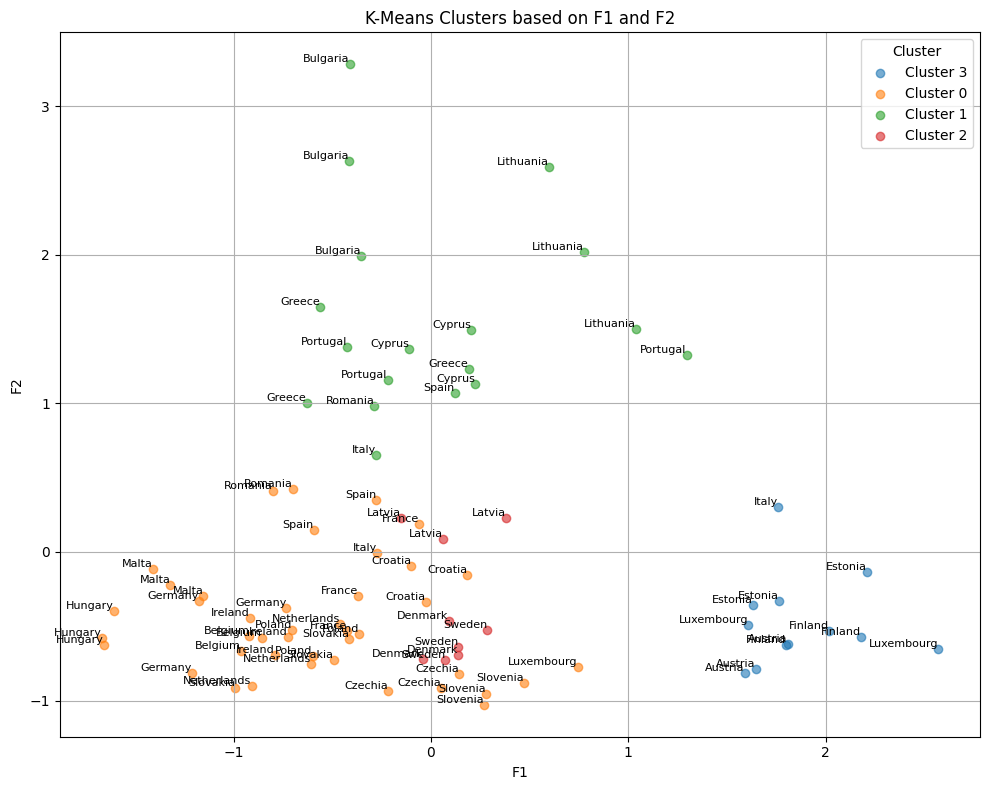

In [58]:
clusters = df_cfs_factors['kmeans_cluster'].unique()
colors = plt.cm.get_cmap('tab10', len(clusters))

plt.figure(figsize=(10, 8))
for cluster in clusters:
    cluster_data = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster]
    plt.scatter(cluster_data['F1'], cluster_data['F2'],
                label=f'Cluster {cluster}',
                alpha=0.6)

for country, row in df_cfs_factors.iterrows():
    plt.text(row['F1'], row['F2'], country, fontsize=8, ha='right', va='bottom')

plt.xlabel('F1')
plt.ylabel('F2')
plt.title('K-Means Clusters based on F1 and F2')
plt.legend(title='Cluster')
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\Pedro Salgado\AppData\Local\Temp\ipykernel_15112\3043117526.py:2: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



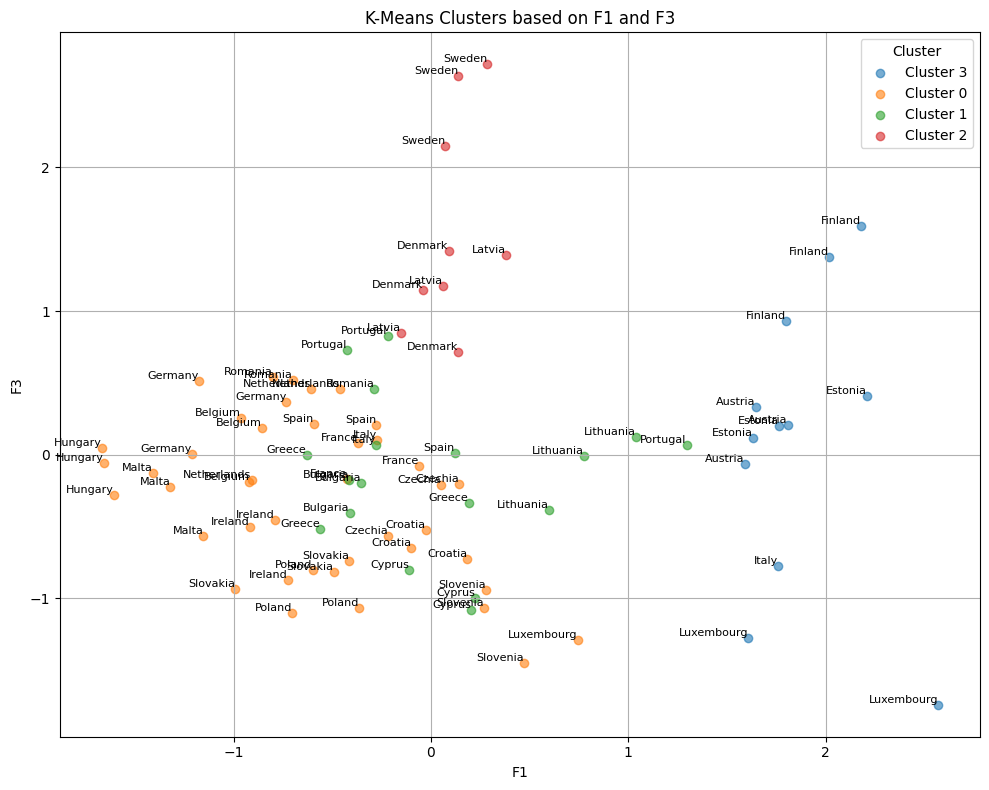

In [59]:
clusters = df_cfs_factors['kmeans_cluster'].unique()
colors = plt.cm.get_cmap('tab10', len(clusters))

plt.figure(figsize=(10, 8))
for cluster in clusters:
    cluster_data = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster]
    plt.scatter(cluster_data['F1'], cluster_data['F3'],
                label=f'Cluster {cluster}',
                alpha=0.6)

for country, row in df_cfs_factors.iterrows():
    plt.text(row['F1'], row['F3'], country, fontsize=8, ha='right', va='bottom')

plt.xlabel('F1')
plt.ylabel('F3')
plt.title('K-Means Clusters based on F1 and F3')
plt.legend(title='Cluster')
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\Pedro Salgado\AppData\Local\Temp\ipykernel_15112\2308754485.py:11: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.



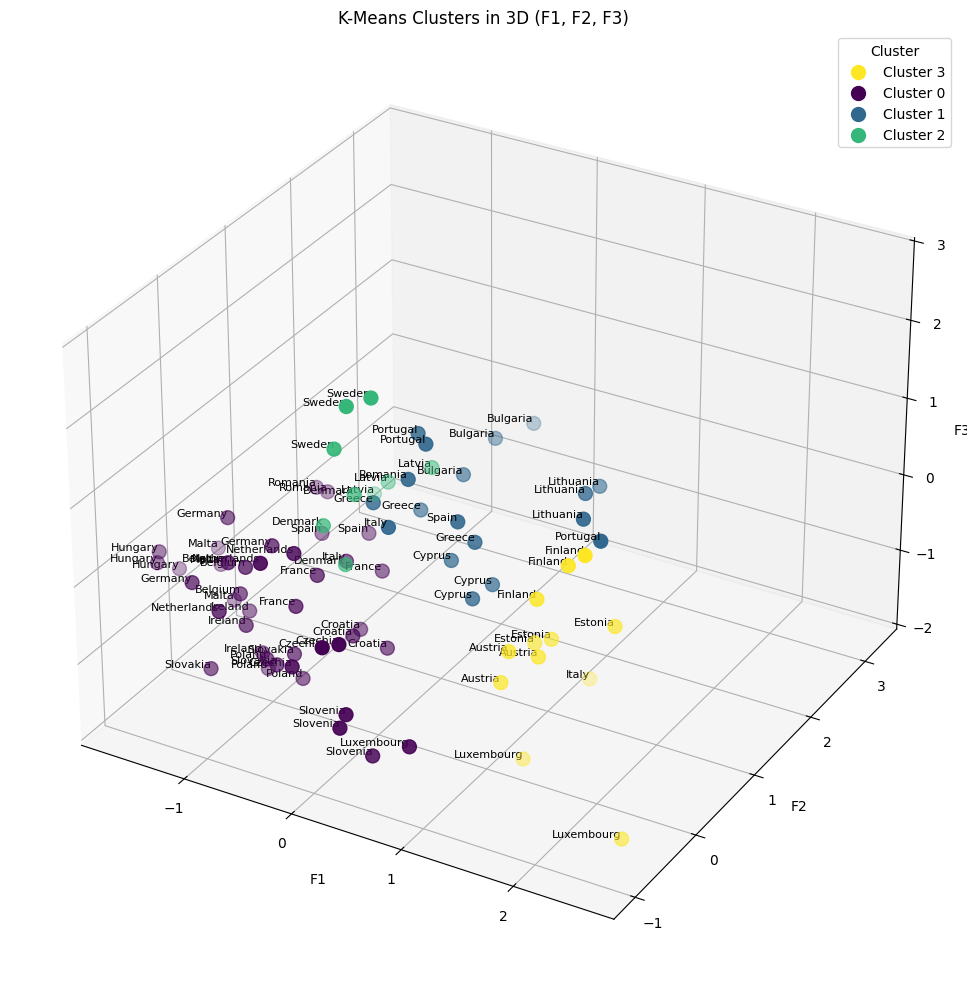

In [60]:
from mpl_toolkits.mplot3d import Axes3D

# Create a new figure and a 3D subplot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Get the unique K-Means cluster labels
clusters = df_cfs_factors['kmeans_cluster'].unique()

# Initialize a colormap
colors = plt.cm.get_cmap('viridis', len(clusters))

# Iterate through each unique cluster and plot
for cluster in clusters:
    cluster_data = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster]
    ax.scatter(
        cluster_data['F1'],
        cluster_data['F2'],
        cluster_data['F3'],
        label=f'Cluster {cluster}',
        color=colors(cluster / len(clusters)),
        s=100  # Marker size
    )

    # Annotate country names
    for country, row in cluster_data.iterrows():
        ax.text(row['F1'], row['F2'], row['F3'], country, fontsize=8, ha='right', va='bottom')

# Set labels and title
ax.set_xlabel('F1')
ax.set_ylabel('F2')
ax.set_zlabel('F3')
ax.set_title('K-Means Clusters in 3D (F1, F2, F3)')

# Display legend
ax.legend(title='Cluster')

# Show the plot
plt.tight_layout()
plt.show()

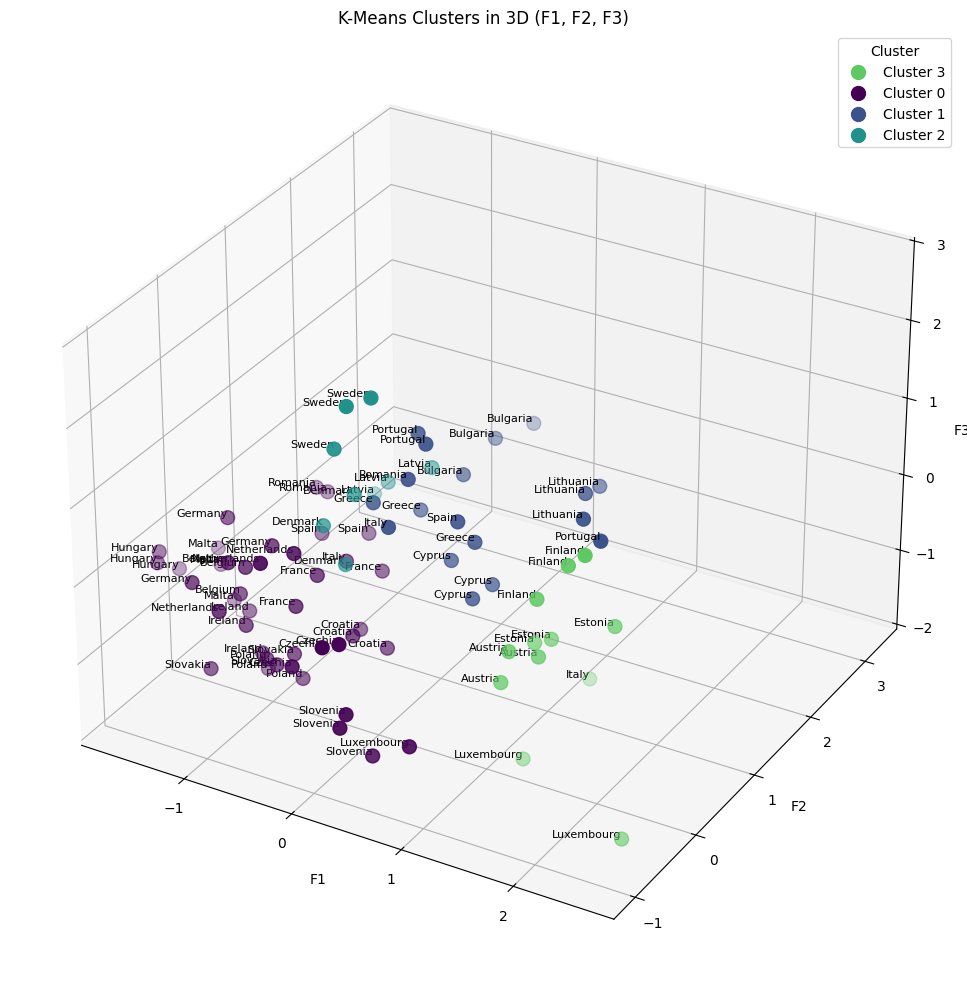

In [61]:
from mpl_toolkits.mplot3d import Axes3D

# Create a new figure and a 3D subplot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Get the unique K-Means cluster labels
clusters = df_cfs_factors['kmeans_cluster'].unique()

# Initialize a colormap using the recommended method to avoid deprecation warning
colors = plt.colormaps.get_cmap('viridis')

# Iterate through each unique cluster and plot
for cluster in clusters:
    cluster_data = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster]
    ax.scatter(
        cluster_data['F1'],
        cluster_data['F2'],
        cluster_data['F3'],
        label=f'Cluster {cluster}',
        color=colors(cluster / len(clusters)),
        s=100  # Marker size
    )

    # Annotate country names
    for country, row in cluster_data.iterrows():
        ax.text(row['F1'], row['F2'], row['F3'], country, fontsize=8, ha='right', va='bottom')

# Set labels and title
ax.set_xlabel('F1')
ax.set_ylabel('F2')
ax.set_zlabel('F3')
ax.set_title('K-Means Clusters in 3D (F1, F2, F3)')

# Display legend
ax.legend(title='Cluster')

# Show the plot
plt.tight_layout()
plt.show()

In [62]:
cluster_means

,F1,F2,F3
kmeans_cluster,,,
0,-0.579326,-0.467521,-0.306387
1,0.042434,1.581353,-0.146241
2,0.109105,-0.357600,1.576158
3,1.882161,-0.467504,0.109596


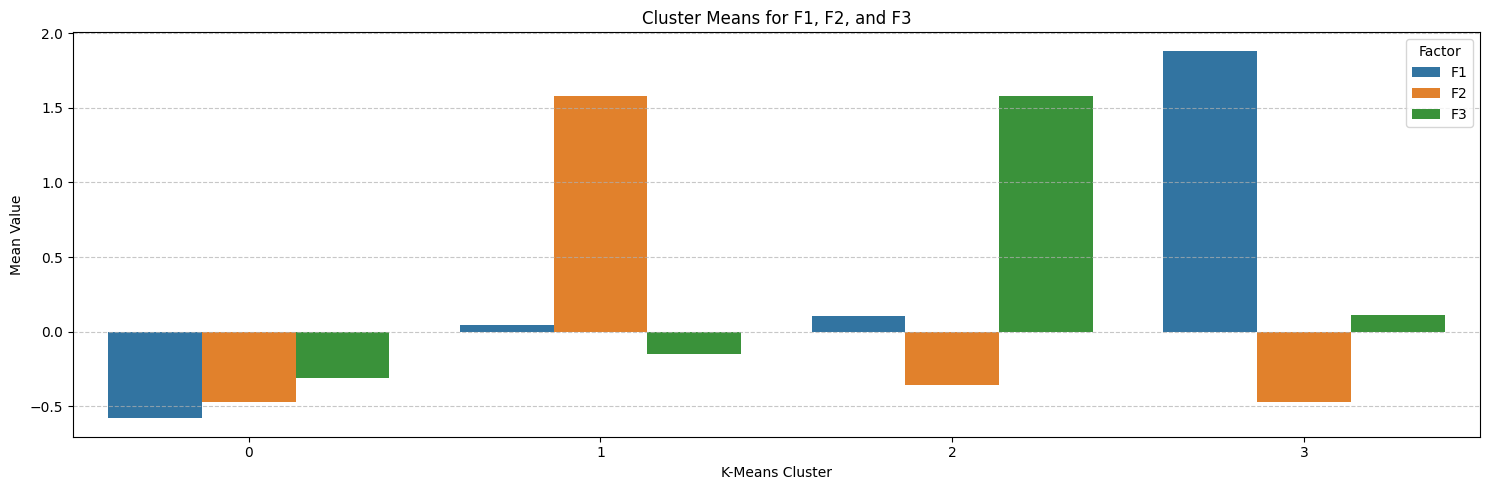

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = cluster_means.reset_index().melt(id_vars='kmeans_cluster', var_name='Factor', value_name='Mean_Value')

plt.figure(figsize=(15, 5))
sns.barplot(x='kmeans_cluster', y='Mean_Value', hue='Factor', data=plot_data)
plt.title('Cluster Means for F1, F2, and F3')
plt.xlabel('K-Means Cluster')
plt.ylabel('Mean Value')
plt.legend(title='Factor')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [64]:
for cluster_id in sorted(df_cfs_factors['kmeans_cluster'].unique()):
    countries_in_cluster = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster_id].index.tolist()
    print(f"Cluster {cluster_id}: {', '.join(countries_in_cluster)}")

Cluster 0: Belgium, Belgium, Belgium, Croatia, Croatia, Croatia, Czechia, Czechia, Czechia, France, France, France, Germany, Germany, Germany, Hungary, Hungary, Hungary, Ireland, Ireland, Ireland, Italy, Luxembourg, Malta, Malta, Malta, Netherlands, Netherlands, Netherlands, Poland, Poland, Poland, Romania, Romania, Slovakia, Slovakia, Slovakia, Slovenia, Slovenia, Slovenia, Spain, Spain
Cluster 1: Bulgaria, Bulgaria, Bulgaria, Cyprus, Cyprus, Cyprus, Greece, Greece, Greece, Italy, Lithuania, Lithuania, Lithuania, Portugal, Portugal, Portugal, Romania, Spain
Cluster 2: Denmark, Denmark, Denmark, Latvia, Latvia, Latvia, Sweden, Sweden, Sweden
Cluster 3: Austria, Austria, Austria, Estonia, Estonia, Estonia, Finland, Finland, Finland, Italy, Luxembourg, Luxembourg


In [65]:
df_cfs_factors = df_cfs_factors.reset_index()
df_cfs_factors.head()

,Country,F1,F2,F3,kmeans_cluster
0,Austria,1.589466,-0.812677,-0.062937,3
1,Austria,1.645349,-0.786968,0.331630,3
2,Austria,1.808834,-0.616133,0.208787,3
3,Belgium,-0.919434,-0.567988,-0.192766,0
4,Belgium,-0.962587,-0.664640,0.258340,0


In [66]:
import country_converter as cc

print("country_converter imported as cc.")

country_converter imported as cc.


In [67]:
df_cfs_factors['ISO_A2'] = df_cfs_factors['Country'].apply(lambda x: cc.convert(names=x, to='ISO2'))
print("ISO Alpha-2 codes added to 'df_cfs_factors'.")

ISO Alpha-2 codes added to 'df_cfs_factors'.


In [68]:
def get_flag_emoji(iso_code):
    if pd.isna(iso_code) or len(iso_code) != 2:
        return ""
    return ''.join(chr(0x1F1E6 + ord(c) - ord('A')) for c in iso_code.upper())

df_cfs_factors['Flag_Emoji'] = df_cfs_factors['ISO_A2'].apply(get_flag_emoji)
print("Flag emojis added to 'df_cfs_factors'.")

Flag emojis added to 'df_cfs_factors'.


In [69]:
df_cfs_factors.head()

,Country,F1,F2,F3,kmeans_cluster,ISO_A2,Flag_Emoji
0,Austria,1.589466,-0.812677,-0.062937,3,AT,🇦🇹
1,Austria,1.645349,-0.786968,0.331630,3,AT,🇦🇹
2,Austria,1.808834,-0.616133,0.208787,3,AT,🇦🇹
3,Belgium,-0.919434,-0.567988,-0.192766,0,BE,🇧🇪
4,Belgium,-0.962587,-0.664640,0.258340,0,BE,🇧🇪


In [70]:
import plotly.express as px

# Define a new, distinct color map for the clusters, avoiding yellow
cluster_colors = {
    0: '#1b9e77', # Green
    1: '#d95f02', # Orange-brown
    2: '#7570b3', # Purple
    3: '#e7298a'  # Pink/Magenta
}
# Ensure the order of the clusters in the legend
cluster_category_order = [0, 1, 2, 3]

# Create an interactive scatter plot for F1 vs F2 with Flag Emojis
fig_f1_f2 = px.scatter(
    df_cfs_factors,
    x='F1',
    y='F2',
    color='kmeans_cluster',
    text='Flag_Emoji',
    hover_name='Country',
    title='K-Means Clusters based on F1 and F2 (with Flag Emojis - Plotly)',
    labels={'F1': 'Factor 1', 'F2': 'Factor 2'},
    color_discrete_map=cluster_colors, # Explicitly map colors
    category_orders={'kmeans_cluster': cluster_category_order} # Explicitly order legend
)

# Update traces to make markers larger and add an outline for visual grouping
fig_f1_f2.update_traces(
    textposition='top center',
    marker=dict(size=12, line=dict(width=1, color='DarkSlateGrey'))
)
fig_f1_f2.update_layout(
    xaxis_title='F1',
    yaxis_title='F2',
    legend_title='Cluster'
)
fig_f1_f2.show()

In [71]:
import plotly.express as px

# Define a new, distinct color map for the clusters, avoiding yellow
cluster_colors = {
    0: '#1b9e77', # Green
    1: '#d95f02', # Orange-brown
    2: '#7570b3', # Purple
    3: '#e7298a'  # Pink/Magenta
}
# Ensure the order of the clusters in the legend
cluster_category_order = [0, 1, 2, 3]

# Create an interactive scatter plot for F1 vs F3 with Flag Emojis
fig_f1_f3 = px.scatter(
    df_cfs_factors,
    x='F1',
    y='F3',
    color='kmeans_cluster',
    text='Flag_Emoji',
    hover_name='Country',
    title='K-Means Clusters based on F1 and F3 (with Flag Emojis - Plotly)',
    labels={'F1': 'Factor 1', 'F3': 'Factor 3'},
    color_discrete_map=cluster_colors, # Explicitly map colors
    category_orders={'kmeans_cluster': cluster_category_order} # Explicitly order legend
)

# Update traces to make markers larger and add an outline for visual grouping
fig_f1_f3.update_traces(
    textposition='top center',
    marker=dict(size=12, line=dict(width=1, color='DarkSlateGrey'))
)
fig_f1_f3.update_layout(
    xaxis_title='F1',
    yaxis_title='F3',
    legend_title='Cluster'
)
fig_f1_f3.show()

In [72]:
import plotly.express as px

# Define a new, distinct color map for the clusters, avoiding yellow
cluster_colors = {
    0: '#1b9e77', # Green
    1: '#d95f02', # Orange-brown
    2: '#7570b3', # Purple
    3: '#e7298a'  # Pink/Magenta
}
# Ensure the order of the clusters in the legend
cluster_category_order = [0, 1, 2, 3]

# Create an interactive 3D line plot
fig_3d_line = px.line_3d(
    df_cfs_factors, # Changed from df_plot_3d to df_cfs_factors
    x='F1',
    y='F2',
    z='F3',
    color='kmeans_cluster',
    line_group='kmeans_cluster', # Group lines by cluster
    hover_name='Country',
    hover_data=['Flag_Emoji'],
    title='K-Means Clusters in 3D (F1, F2, F3) with Closed Lines',
    labels={'F1': 'Factor 1', 'F2': 'Factor 2', 'F3': 'Factor 3'},
    color_discrete_map=cluster_colors,
    category_orders={'kmeans_cluster': cluster_category_order}
)

# Update traces to display both lines and markers
fig_3d_line.update_traces(mode='lines+markers', marker=dict(size=5))

# Display the plot
fig_3d_line.show()

In [73]:
!pip install -U kaleido


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [74]:
import plotly.express as px
import plotly.graph_objects as go
from scipy.spatial import ConvexHull
import numpy as np

cluster_colors = {
    0: '#1f77b4',
    1: '#ff7f0e',
    2: '#2ca02c',
    3: '#d62728'
}
cluster_order = [0, 1, 2, 3]

fig = px.scatter(
    df_cfs_factors,
    x='F1',
    y='F2',
    color='kmeans_cluster',
    text='Flag_Emoji',
    hover_name='Country',
    title='K-Means Clusters (EIGI vs SEEV)',
    labels={'F1': 'EIGI', 'F2': 'SEEV'},
    color_discrete_map=cluster_colors,
    category_orders={'kmeans_cluster': cluster_order}
)

fig.update_traces(
    textposition='top center',
    marker=dict(size=12, line=dict(width=1, color='DarkSlateGrey'))
)

for cluster in cluster_order:
    subset = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster]
    if len(subset) >= 3:
        points = subset[['F1','F2']].to_numpy()
        hull = ConvexHull(points)
        hull_pts = points[hull.vertices]
        fig.add_trace(
            go.Scatter(
                x=hull_pts[:,0],
                y=hull_pts[:,1],
                fill='toself',
                mode='lines',
                line=dict(color=cluster_colors[cluster], width=2),
                hoverinfo='skip',
                showlegend=False
            )
        )

fig.update_layout(xaxis_title='EIGI', yaxis_title='SEEV', legend_title='Cluster')
fig.show()

In [75]:
import plotly.express as px
import plotly.graph_objects as go
from scipy.spatial import ConvexHull
import numpy as np

cluster_colors = {
    0: '#1f77b4',
    1: '#ff7f0e',
    2: '#2ca02c',
    3: '#d62728'
}
cluster_order = [0, 1, 2, 3]

fig = px.scatter(
    df_cfs_factors,
    x='F1',
    y='F3',
    color='kmeans_cluster',
    text='Flag_Emoji',
    hover_name='Country',
    title='K-Means Clusters (EIGI vs CEEP)',
    labels={'F1': 'EIGI', 'F3': 'CEEP'},
    color_discrete_map=cluster_colors,
    category_orders={'kmeans_cluster': cluster_order}
)

fig.update_traces(
    textposition='top center',
    marker=dict(size=12, line=dict(width=1, color='DarkSlateGrey'))
)

for cluster in cluster_order:
    subset = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster]
    if len(subset) >= 3:
        points = subset[['F1','F3']].to_numpy()
        hull = ConvexHull(points)
        hull_pts = points[hull.vertices]
        fig.add_trace(
            go.Scatter(
                x=hull_pts[:,0],
                y=hull_pts[:,1],
                fill='toself',
                mode='lines',
                line=dict(color=cluster_colors[cluster], width=2),
                hoverinfo='skip',
                showlegend=False
            )
        )

fig.update_layout(xaxis_title='EIGI', yaxis_title='CEEP', legend_title='Cluster')
fig.show()



In [76]:
import plotly.express as px
import plotly.graph_objects as go
from scipy.spatial import ConvexHull
import numpy as np

cluster_colors = {
    0: '#1f77b4',
    1: '#ff7f0e',
    2: '#2ca02c',
    3: '#d62728'
}
cluster_order = [0, 1, 2, 3]

fig = px.scatter(
    df_cfs_factors,
    x='F2',
    y='F3',
    color='kmeans_cluster',
    text='Flag_Emoji',
    hover_name='Country',
    title='K-Means Clusters (SEEV vs CEEP)',
    labels={'F2': 'SEEV', 'F3': 'CEEP'},
    color_discrete_map=cluster_colors,
    category_orders={'kmeans_cluster': cluster_order}
)

fig.update_traces(
    textposition='top center',
    marker=dict(size=12, line=dict(width=1, color='DarkSlateGrey'))
)

for cluster in cluster_order:
    subset = df_cfs_factors[df_cfs_factors['kmeans_cluster'] == cluster]
    if len(subset) >= 3:
        points = subset[['F2','F3']].to_numpy()
        hull = ConvexHull(points)
        hull_pts = points[hull.vertices]
        fig.add_trace(
            go.Scatter(
                x=hull_pts[:,0],
                y=hull_pts[:,1],
                fill='toself',
                mode='lines',
                line=dict(color=cluster_colors[cluster], width=2),
                hoverinfo='skip',
                showlegend=False
            )
        )

fig.update_layout(xaxis_title='SEEV', yaxis_title='CEEP', legend_title='Cluster')
fig.show()


In [77]:
country_cluster_counts = df_cfs_factors.groupby(['Country', 'kmeans_cluster']).size().reset_index(name='count')

# Find the cluster with the maximum count for each country
# If a country has multiple entries in different clusters, it will be assigned to the cluster it appears most in
most_frequent_cluster = country_cluster_counts.loc[country_cluster_counts.groupby('Country')['count'].idxmax()]

# Group by the most frequent cluster and list the countries
clusters_with_unique_countries = {}
for cluster_id in sorted(most_frequent_cluster['kmeans_cluster'].unique()):
    countries_in_cluster = most_frequent_cluster[most_frequent_cluster['kmeans_cluster'] == cluster_id]['Country'].tolist()
    clusters_with_unique_countries[cluster_id] = countries_in_cluster

for cluster_id, countries in clusters_with_unique_countries.items():
    print(f"Cluster {cluster_id}: {', '.join(countries)}")

Cluster 0: Belgium, Croatia, Czechia, France, Germany, Hungary, Ireland, Italy, Malta, Netherlands, Poland, Romania, Slovakia, Slovenia, Spain
Cluster 1: Bulgaria, Cyprus, Greece, Lithuania, Portugal
Cluster 2: Denmark, Latvia, Sweden
Cluster 3: Austria, Estonia, Finland, Luxembourg
